In [1]:
import scanpy as sc
import pandas as pd
import numpy as np

In [4]:
adata = sc.read_h5ad('./data/scncc_with_nocancer_anno.h5ad')

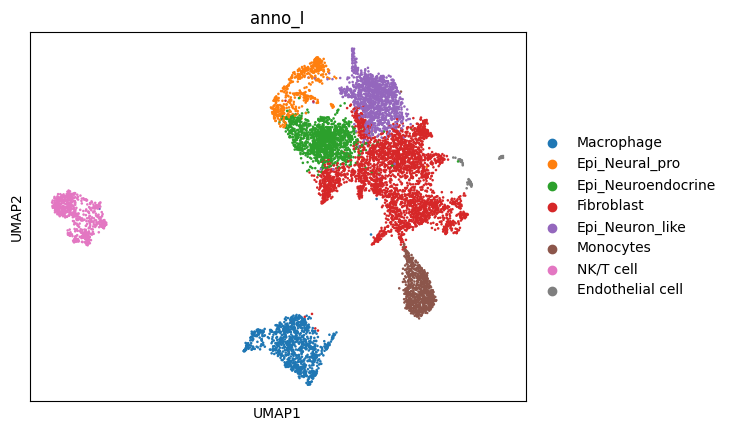

In [5]:
sc.pl.umap(adata, color='anno_I')

In [6]:
select_ct = ['Monocytes', 'Macrophage']
sub_adata = adata[adata.obs['anno_I'].isin(select_ct)].copy()
sub_adata

AnnData object with n_obs × n_vars = 1782 × 18939
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [7]:
sub_adata.X = sub_adata.layers['counts'].copy()
sc.pp.filter_genes(sub_adata, min_cells=3)
sub_adata

AnnData object with n_obs × n_vars = 1782 × 14489
    obs: 'barcodes', 'batch', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'total_counts_hb', 'pct_counts_hb', 'total_counts_hsp', 'pct_counts_hsp', 'n_genes', 'group', 'predicted_celltype', 'predicted_probability', 'leiden', 'anno_I'
    var: 'mt', 'rb', 'hb', 'hsp', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'anno_I_colors', 'batch_colors', 'group_colors', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'over_clustering', 'pca', 'predicted_celltype_colors', 'rank_genes_groups', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [8]:
sc.pp.normalize_total(sub_adata, target_sum=1e4)
sc.pp.log1p(sub_adata)

In [9]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    layer="counts",
    flavor="seurat_v3",
    batch_key="batch",
)

In [10]:
sc.pp.regress_out(sub_adata, ["total_counts", "pct_counts_mt", 'n_genes_by_counts'], n_jobs=4)

In [11]:
sc.pp.pca(sub_adata, svd_solver="arpack")

In [13]:
sc.external.pp.harmony_integrate(sub_adata, key='batch', max_iter_harmony=20)

2025-11-30 17:51:28,266 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2025-11-30 17:51:32,804 - harmonypy - INFO - sklearn.KMeans initialization complete.
2025-11-30 17:51:32,881 - harmonypy - INFO - Iteration 1 of 20
2025-11-30 17:51:33,575 - harmonypy - INFO - Iteration 2 of 20
2025-11-30 17:51:34,198 - harmonypy - INFO - Iteration 3 of 20
2025-11-30 17:51:34,735 - harmonypy - INFO - Iteration 4 of 20
2025-11-30 17:51:35,375 - harmonypy - INFO - Iteration 5 of 20
2025-11-30 17:51:35,640 - harmonypy - INFO - Iteration 6 of 20
2025-11-30 17:51:35,972 - harmonypy - INFO - Iteration 7 of 20
2025-11-30 17:51:36,259 - harmonypy - INFO - Iteration 8 of 20
2025-11-30 17:51:36,475 - harmonypy - INFO - Iteration 9 of 20
2025-11-30 17:51:36,708 - harmonypy - INFO - Iteration 10 of 20
2025-11-30 17:51:36,987 - harmonypy - INFO - Iteration 11 of 20
2025-11-30 17:51:37,180 - harmonypy - INFO - Iteration 12 of 20
2025-11-30 17:51:37,459 - harmonypy - INFO - Iteration 13 of

In [14]:
sc.pp.neighbors(sub_adata, n_neighbors=15, use_rep="X_pca_harmony", random_state=0)

/usr/local/lib/python3.9/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [15]:
sc.tl.leiden(sub_adata, resolution = 0.3, flavor = 'igraph', n_iterations=-1)
sc.tl.umap(sub_adata, min_dist=0.7)

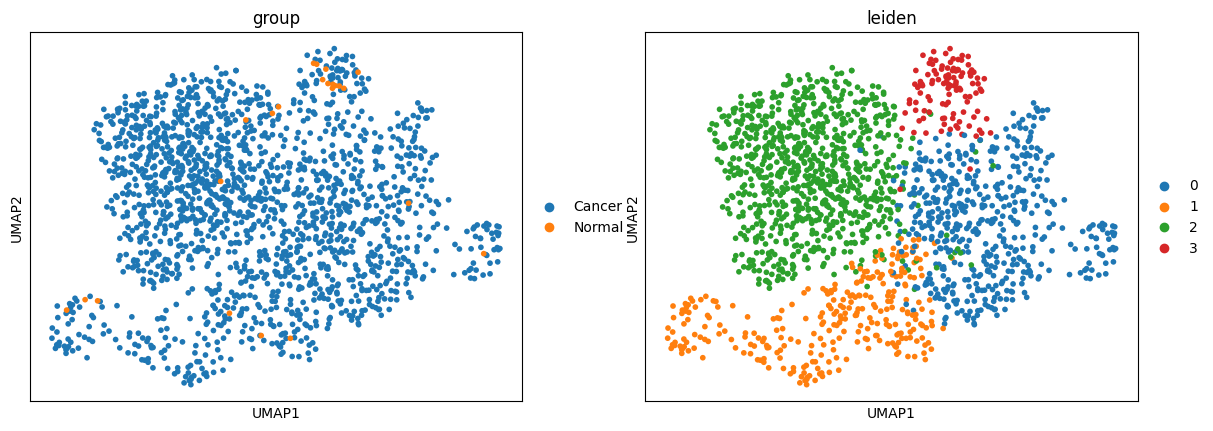

In [16]:
sc.pl.umap(sub_adata, color=['group', 'leiden'])

In [17]:
sc.tl.rank_genes_groups(sub_adata, "leiden", method="wilcoxon")

In [18]:
dfs = []
for g in sub_adata.obs["leiden"].cat.categories:
    df = sc.get.rank_genes_groups_df(sub_adata, group=g)
    df["cluster"] = g
    dfs.append(df)
markers = pd.concat(dfs, ignore_index=True)

In [19]:
marker_df = markers.assign(row_index=markers.groupby('cluster').cumcount()).pivot_table(index='row_index', columns='cluster', values='names',  aggfunc='first')
marker_df.index.name = None
marker_df.columns.name = None
marker_df.loc[1:100].to_csv('sub_myeloid_marker.csv')

In [27]:
anno_mapping = {
    "0": "TAMs", # ANGPTL4, C1QA, CD14, CD163, CD68, CST3, GPNMB
    "1": "DC", # ANXA1, FCN1, HBEGF, IL1B, NLRP3, VCAN
    "2": "Classical monocyte", # A100A9, FCGR3B, S100A12, S100A4, S100A6, S100A8
    "3": "Plasma" # PDIA6, RABAC1, SEC61B, TMED2
}

sub_adata.obs['anno_II'] = sub_adata.obs['leiden'].replace(anno_mapping)

In [33]:
marker_dict = {
    "TAMs": [i for i in ["ANGPTL4", "CD68", "CST3", "GPNMB"] if i in sub_adata.var_names],
    "Classical monocyte": [i for i in ["A100A9", "FCGR3B", "S100A12", "S100A4"] if i in sub_adata.var_names],
    "DC": [i for i in ["FCN1", "HBEGF", "IL1B", "NLRP3", "VCAN"] if i in sub_adata.var_names],
    "Plasma": [i for i in ["SEC11C", "XBP1"] if i in sub_adata.var_names]
}

In [22]:
import seaborn as sns
from matplotlib import colors
import matplotlib.pyplot as plt

import matplotlib.font_manager as fm
font_dir = '/./font/'
for ttf in fm.findSystemFonts(font_dir):
    fm.fontManager.addfont(ttf)

import matplotlib
#plt.rcParams['font.family'] = 'Times New Roman'
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

import logging
logging.getLogger("fontTools.subset").setLevel(logging.WARNING)

In [2]:
sub_adata = sc.read_h5ad('./sub_myeloid.h5ad')

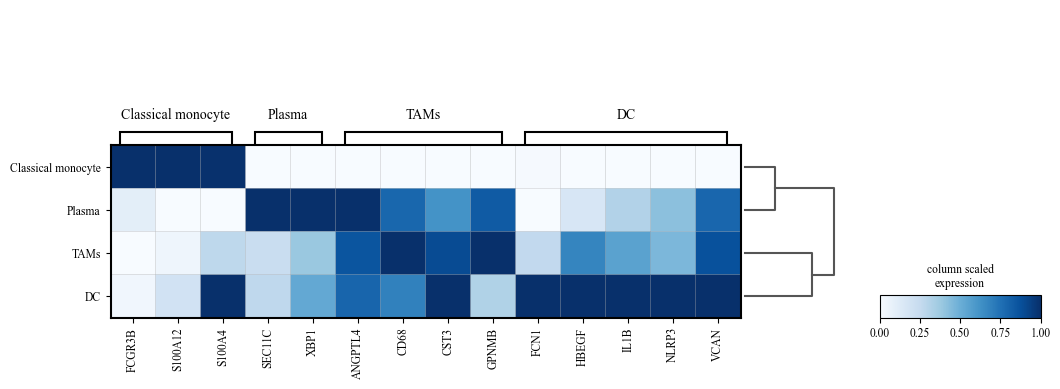

In [66]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4))
sc.pl.matrixplot(sub_adata, marker_dict, 'anno_II', cmap='Blues', dendrogram=True, standard_scale="var", colorbar_title='column scaled\nexpression', ax=ax, var_group_rotation=0, show=False)
plt.savefig('./fig/fig6_mye_marker_expression.pdf', format='pdf')

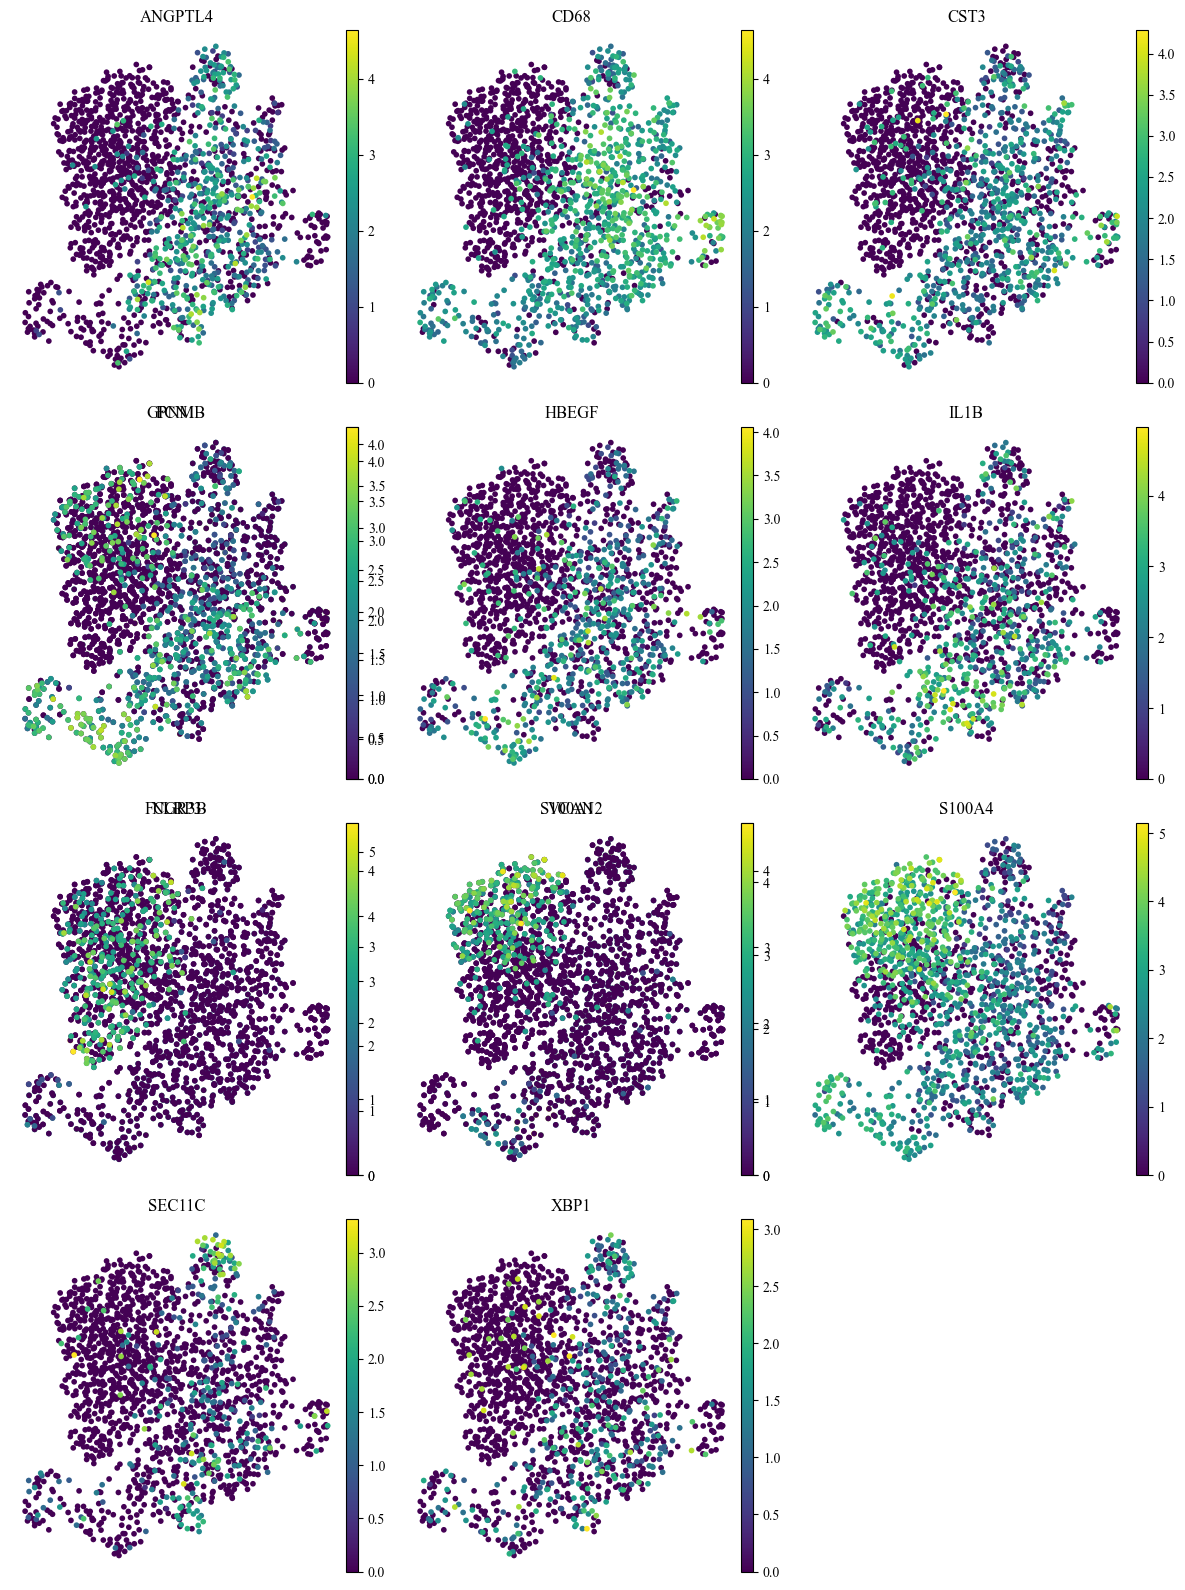

In [53]:
n_top = 3
leiden_key = 'anno_II'
cmp = 'viridis'

clusters = sub_adata.obs[leiden_key].cat.categories
n_clust = len(clusters)

# 2. 画布：每行 3 张，行数 = 群数
cols = 3
rows = n_clust
fig = plt.figure(figsize=(4 * cols, 4 * rows))

# 3. 画图
for i, clu in enumerate(clusters):
    top_genes = marker_dict[clu]
    for j, g in enumerate(top_genes):
        ax = fig.add_subplot(rows, cols, i*cols + j + 1)  # 先行后列
        sc.pl.umap(sub_adata, color=g, ax=ax, show=False,
                   frameon=False, title=g, color_map=cmp)

plt.tight_layout()
plt.savefig('./fig/fig6_mye_anno_umap.pdf', format='pdf', bbox_inches='tight', pad_inches=0.2)
plt.show()

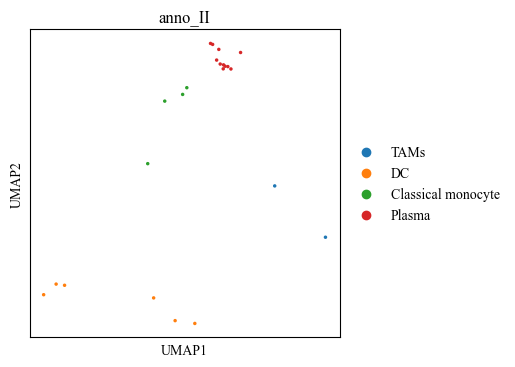

In [54]:
fig, ax = plt.subplots(figsize=(4, 4))
sc.pl.umap(sub_adata[sub_adata.obs['group'] == 'Normal'], color='anno_II', show=False, ax=ax, size=25)
plt.savefig('./fig/fig6_mye_normal_umap.pdf', format='pdf')

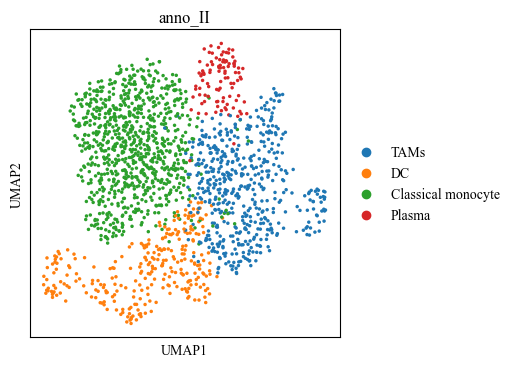

In [55]:
fig, ax = plt.subplots(figsize=(4, 4))
sc.pl.umap(sub_adata[sub_adata.obs['group'] == 'Cancer'], color='anno_II', show=False, ax=ax, size=25)
plt.savefig('./fig/fig6_mye_cancer_umap.pdf', format='pdf')

In [4]:
df = pd.crosstab(sub_adata.obs['group'], sub_adata.obs['anno_II']).div(pd.crosstab(sub_adata.obs['group'], sub_adata.obs['anno_II']).sum(axis=1), axis=0)

In [5]:
df

anno_II,TAMs,DC,Classical monocyte,Plasma
group,,,,
Cancer,0.292211,0.162024,0.489483,0.056282
Normal,0.086957,0.260870,0.173913,0.478261


findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times New Roman' not found.
findfont: Font family 'Times Ne

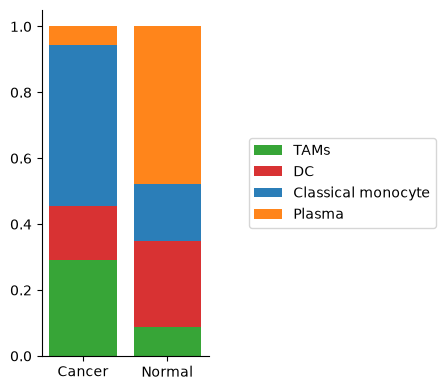

In [6]:
fig, ax = plt.subplots(figsize=(5, 4))

celltype2color = {
    'TAMs': '#2ca02c',
    'Plasma': '#ff7f0e',
    'Classical monocyte': '#1f77b4',
    'DC': '#d62728',
}

bottom = [0] * len(df)
for ct in df.columns:
    ax.bar(df.index, df[ct], bottom=bottom, label=ct, alpha=0.95, color=celltype2color[ct])
    bottom = [i+j for i,j in zip(bottom, df[ct])]
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
ax.legend(title="", loc='center left', bbox_to_anchor=(1.2, 0.5))
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("./fig/fig6_cancer-normal_ratio.pdf", format='pdf')
plt.show()

In [59]:
df = pd.crosstab(sub_adata.obs['anno_II'], sub_adata.obs['group']).div(pd.crosstab(sub_adata.obs['anno_II'], sub_adata.obs['group']).sum(axis=1), axis=0)
df

group,Cancer,Normal
anno_II,,
TAMs,0.996124,0.003876
DC,0.979381,0.020619
Classical monocyte,0.995376,0.004624
Plasma,0.900000,0.100000


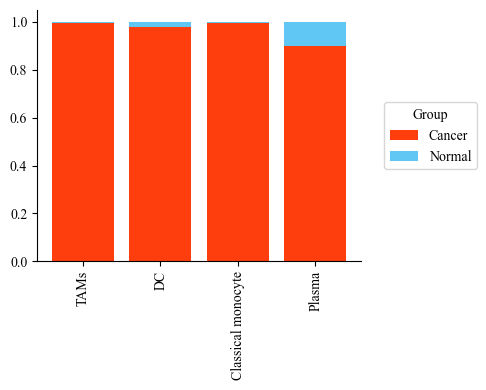

In [60]:
fig, ax = plt.subplots(figsize=(5, 4))

group2color = {'Cancer': '#FF3300', 'Normal': '#57C3F3'}

bottom = [0] * len(df)
for ct in df.columns:
    ax.bar(df.index, df[ct], bottom=bottom, label=ct, alpha=0.95, color=group2color[ct])
    bottom = [i+j for i,j in zip(bottom, df[ct])]
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
    
handles, labels = ax.get_legend_handles_labels()
labels = ['normal' if l == 'non-cancer' else l for l in labels]

legend = ax.legend(handles, labels,
    title = 'Group',
    loc ='center left',
    bbox_to_anchor=(1.05, 0.5),
    frameon = True)
                   
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("./fig/fig6_cancervsnormal_ratio.pdf", format='pdf')
plt.show()

In [61]:
import gseapy as gp

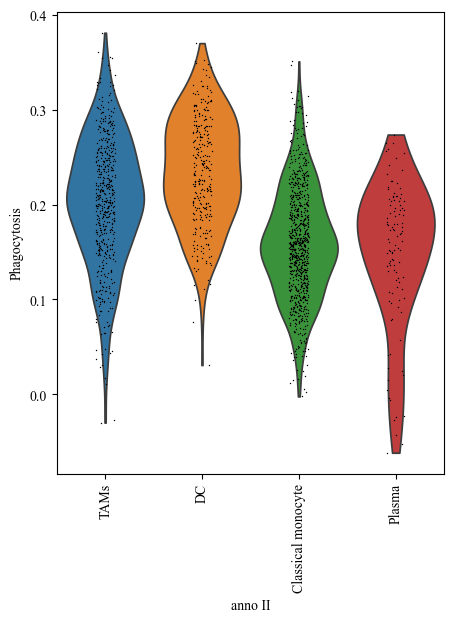

In [62]:
gene_sets = gp.read_gmt("./gmt/GOBP_PHAGOCYTOSIS.v2025.1.Hs.gmt")
gene_list = gene_sets['GOBP_PHAGOCYTOSIS']
gene_list = [i for i in gene_list if i in sub_adata.var_names]

sc.tl.score_genes(sub_adata, gene_list, score_name="Phagocytosis")

fig, ax = plt.subplots(figsize=(5, 6))
sc.pl.violin(sub_adata, "Phagocytosis", groupby='anno_II', ax=ax, show=False)
plt.xticks(rotation=90)
plt.savefig("./fig/fig6_Phagocytosis_score.pdf", format='pdf', bbox_inches='tight', pad_inches=0.2)
plt.show()

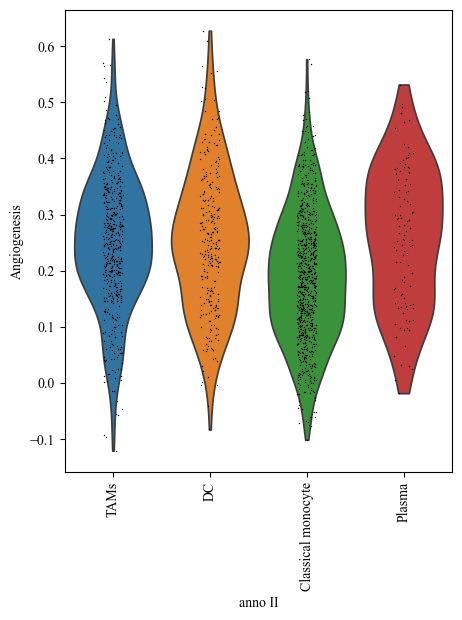

In [63]:
gene_sets = gp.read_gmt("./gmt/ANGIOGENESIS.v2025.1.Hs.gmt")
gene_list = gene_sets['ANGIOGENESIS']
gene_list = [i for i in gene_list if i in sub_adata.var_names]

sc.tl.score_genes(sub_adata, gene_list, score_name="Angiogenesis")

fig, ax = plt.subplots(figsize=(5, 6))
sc.pl.violin(sub_adata, "Angiogenesis", groupby='anno_II', ax=ax, show=False)
plt.xticks(rotation=90)
plt.savefig("./fig/fig6_Angiogenesis_score.pdf", format='pdf', bbox_inches='tight', pad_inches=0.2)
plt.show()

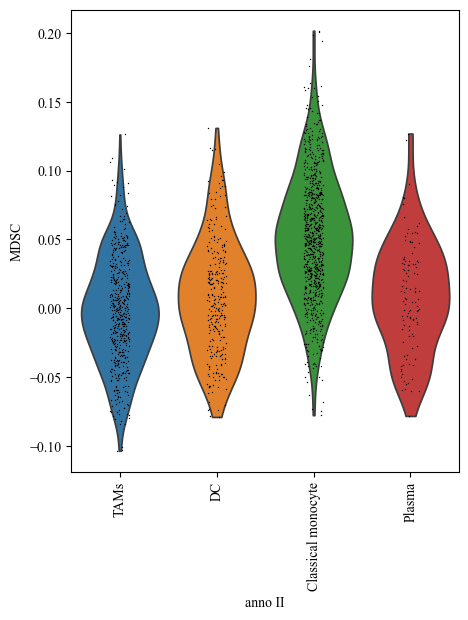

In [64]:
gene_sets = gp.read_gmt("./gmt/GSE24102_GRANULOCYSTIC_MDSC_VS_NEUTROPHIL_UP.v2025.1.Hs.gmt")
gene_list = gene_sets['GSE24102_GRANULOCYSTIC_MDSC_VS_NEUTROPHIL_UP']
gene_list = [i for i in gene_list if i in sub_adata.var_names]

sc.tl.score_genes(sub_adata, gene_list, score_name="MDSC")

fig, ax = plt.subplots(figsize=(5, 6))
sc.pl.violin(sub_adata, "MDSC", groupby='anno_II', ax=ax, show=False)
plt.xticks(rotation=90)
plt.savefig("./fig/fig6_MDSC_score.pdf", format='pdf', bbox_inches='tight', pad_inches=0.2)
plt.show()

In [19]:
def plot_significant_box(plot_df, term, phage=None):
    plt.figure(figsize=(5, 4))

    ax = sns.boxplot(x='plot_group', y=term, data=plot_df, flierprops={'visible': False},
                     order=cell_order, palette=my_colors, width=0.6, linewidth=1)
    #sns.stripplot(x='plot_group', y=term, data=plot_df, order=cell_order, palette=my_colors, size=1, alpha=0.8,
    #             linewidth=1, edgecolor='black')

    ymax = plot_df[term].max()
    height = ymax.max() + ymax*0.01

    plt.xticks(rotation=90)
    plt.ylabel('Score')
    sns.despine()
    plt.tight_layout()
    plt.savefig(f'./fig/fig6_{term}_score.pdf', format='pdf')
    plt.show()

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy import stats

def plot_significant_box(plot_df, term, phage=None):
    plt.figure(figsize=(6, 5)) # 稍微调宽一点，给星号留空间

    # 1. 绘制箱线图和散点图
    ax = sns.boxplot(x='plot_group', y=term, data=plot_df, flierprops={'visible': False},
                     order=cell_order, palette=my_colors, width=0.6, linewidth=1)
    #sns.stripplot(x='plot_group', y=term, data=plot_df, order=cell_order, palette=my_colors, size=3, alpha=0.8, linewidth=0, edgecolor='none') # size稍微调大，去掉了边缘线避免散点太糊

    # 2. 自动进行显著性检验并添加星号
    # 假设你的数据中 Cancer 和 Normal 是成对出现的（基于相同的细胞类型）
    # 遍历 x 轴，寻找需要比较的组
    for i in range(0, len(cell_order), 2):
        group_cancer = cell_order[i]
        group_normal = cell_order[i+1]
        
        # 提取两组数据
        data_cancer = plot_df[plot_df['plot_group'] == group_cancer][term].dropna()
        data_normal = plot_df[plot_df['plot_group'] == group_normal][term].dropna()
        
        # 进行独立样本 t 检验 (如果不满足正态分布，可替换为 stats.mannwhitneyu)
        stat, p_value = stats.ttest_ind(data_cancer, data_normal)
        
        # 定义显著性星号
        if p_value < 0.001:
            sig_symbol = '***'
        elif p_value < 0.01:
            sig_symbol = '**'
        elif p_value < 0.05:
            sig_symbol = '*'
        else:
            sig_symbol = 'ns' # 不显著 (如果不想显示ns，可以改为 continue)
            
        # 计算绘制横线的高度 (取两组数据最大值的较大者，再增加一点偏移)
        max_val = max(data_cancer.max(), data_normal.max())
        y, h = max_val + 0.02, 0.02 # y为基础高度，h为括号高度
        
        # 在当前组的上方画显著性标记线 (x坐标分别为 i 和 i+1)
        # 绘制左侧竖线
        plt.plot([i, i], [y, y + h], lw=1.5, c='k')
        # 绘制右侧竖线
        plt.plot([i+1, i+1], [y, y + h], lw=1.5, c='k')
        # 绘制顶部横线
        plt.plot([i, i+1], [y + h, y + h], lw=1.5, c='k')
        # 添加文本星号
        plt.text((i + i + 1) * 0.5, y + h, sig_symbol, ha='center', va='bottom', color='k', fontsize=12)

    # 3. 调整图表格式
    plt.xticks(rotation=90)
    plt.ylabel('Score', fontsize=12)
    
    # 动态扩展 Y 轴上限，防止标注被截断
    ymin, ymax = plt.ylim()
    plt.ylim(ymin, ymax * 1.15) # 顶部留出 15% 的空间放星号
    
    sns.despine()
    plt.tight_layout()
    
    # 保存图片
    plt.savefig(f'./fig/figmodify6_{term}_score.pdf', format='pdf', dpi=300)
    plt.show()

In [4]:
sub_adata.obs['anno_II'] = sub_adata.obs['anno_II'].cat.rename_categories(
    {
        'Classical monocyte': 'CM'
    }
)

In [5]:
sub_adata.obs['plot_group'] = sub_adata.obs['group'].astype(str) + '_' + sub_adata.obs['anno_II'].astype(str)

In [6]:
cell_order = ['Cancer_TAMs', 'Normal_TAMs', 'Cancer_DC', 'Normal_DC',
              'Cancer_CM', 'Normal_CM', 'Cancer_Plasma', 'Normal_Plasma']
sub_adata.obs['plot_group'] = (
    pd.Categorical(sub_adata.obs['plot_group'],
                  categories=cell_order,
                  ordered=True)
)

palette = sns.color_palette('Set1', n_colors=8)
my_colors = palette.as_hex()
sub_adata.uns['plot_group_colors'] = my_colors

/tmp/ipykernel_47/1212594625.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='plot_group', y=term, data=plot_df, flierprops={'visible': False},


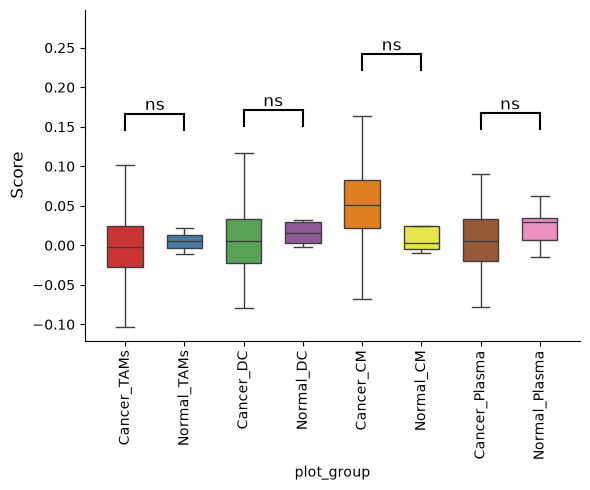

In [23]:
plot_significant_box(sub_adata.obs, 'MDSC')

/tmp/ipykernel_47/1212594625.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='plot_group', y=term, data=plot_df, flierprops={'visible': False},


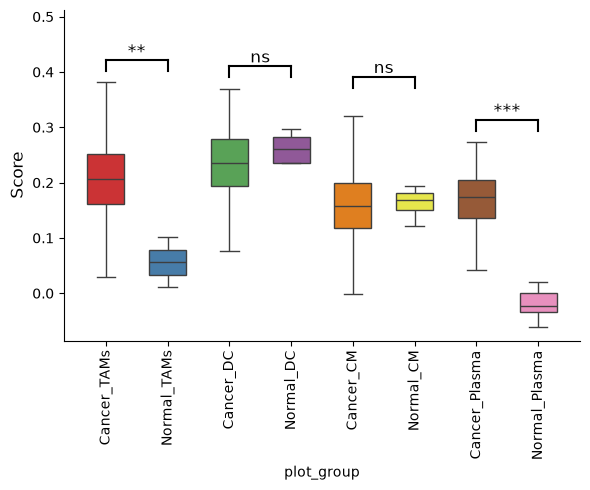

In [24]:
plot_significant_box(sub_adata.obs, 'Phagocytosis')

/tmp/ipykernel_47/1212594625.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='plot_group', y=term, data=plot_df, flierprops={'visible': False},


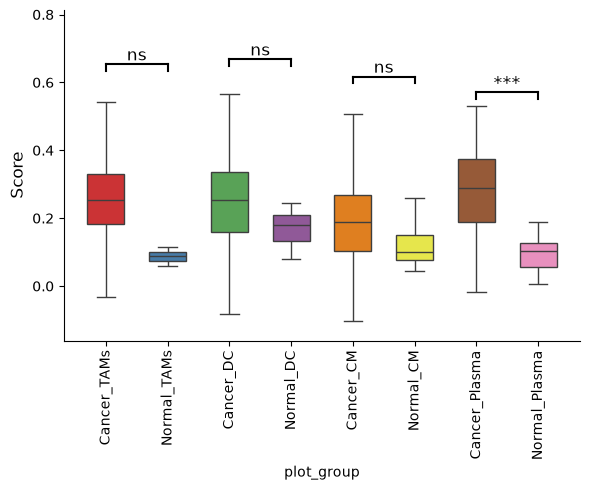

In [25]:
plot_significant_box(sub_adata.obs, 'Angiogenesis')

In [26]:
m1_sig = ['NOS2', 'CXCL9', 'CXCL10', 'CXCL11', 'TNF', 'IL12A', 'IL6', 'IL1B', 'CD80', 'CD86', 'PTGS2', 'IDO1', 'CCL5', 'TLR2', 'HLA-DRA']
sc.tl.score_genes(sub_adata, m1_sig, score_name="M1")

In [27]:
m2_sig = ['MRC1', 'CD163', 'MS4A4A', 'TGM2', 'CCL18', 'CCL22', 'CCL17', 'IL10', 'ARG1', 'FOLR2', 'PDCD1LG2', 'MMP9', 'FN1', 'VEGFA', 'ALOX15']
sc.tl.score_genes(sub_adata, m2_sig, score_name="M2")

/tmp/ipykernel_47/1212594625.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='plot_group', y=term, data=plot_df, flierprops={'visible': False},


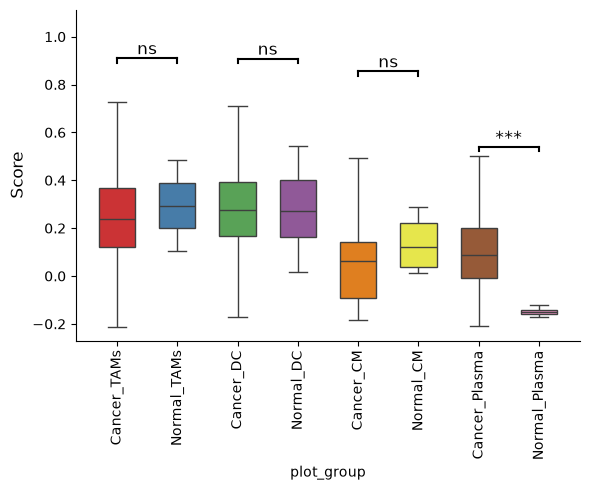

In [28]:
plot_significant_box(sub_adata.obs, 'M1')

/tmp/ipykernel_47/1212594625.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='plot_group', y=term, data=plot_df, flierprops={'visible': False},


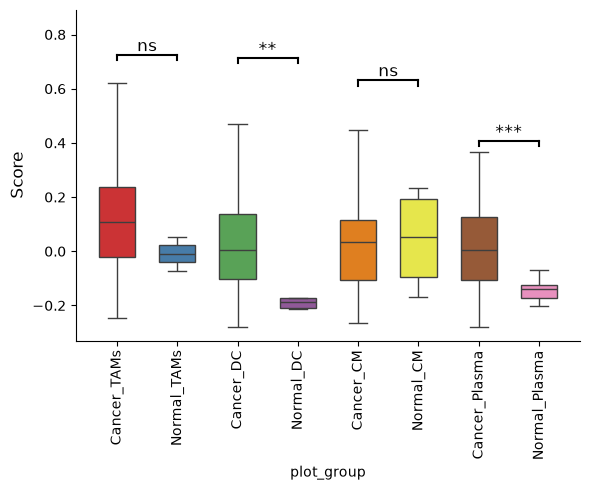

In [29]:
plot_significant_box(sub_adata.obs, 'M2')

In [65]:
sub_adata.write_h5ad('sub_myeloid.h5ad')